# SWYNEX Final Data Science Project
## Titanic Survival Prediction

### 1. Problem Statement

The objective of this project is to analyze the Titanic passenger dataset and build a machine learning model to predict whether a passenger survived the Titanic disaster.

The project follows an end-to-end data science workflow, including data preparation, exploratory data analysis (EDA), feature engineering, model training, evaluation, and conclusions.

### Project Objectives
- Understand the dataset and identify data quality issues.
- Prepare the data for analysis and machine learning.
- Explore survival patterns using statistical summaries and visualizations.
- Build a Logistic Regression classification model.
- Evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix.
- Discuss the results, limitations, and possible improvements.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_titanic.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


## 2. Data Preparation

The Titanic dataset was examined for missing values, duplicate records, and data types before analysis.

### Data Cleaning Steps
- **Age:** Missing values were filled using the median age of 28.
- **Cabin:** Missing values were replaced with the label "Unknown" because cabin information was unavailable for many passengers.
- **Embarked:** Missing values were filled using the mode, which was "S".
- **Duplicates:** Duplicate records were checked, and none were found in the original dataset.
- **Data types:** Column data types were inspected to ensure the data could be used for analysis and modeling.

These decisions helped prepare the dataset for exploratory data analysis and machine learning. Median imputation is less affected by extreme values than mean imputation, while replacing missing cabin values with "Unknown" preserves the fact that the cabin information was unavailable.

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset, identify patterns, and investigate relationships between passenger characteristics and survival outcomes.

### 3.1 Overall Survival Distribution

We first examine how many passengers survived and how many did not survive the Titanic disaster.

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


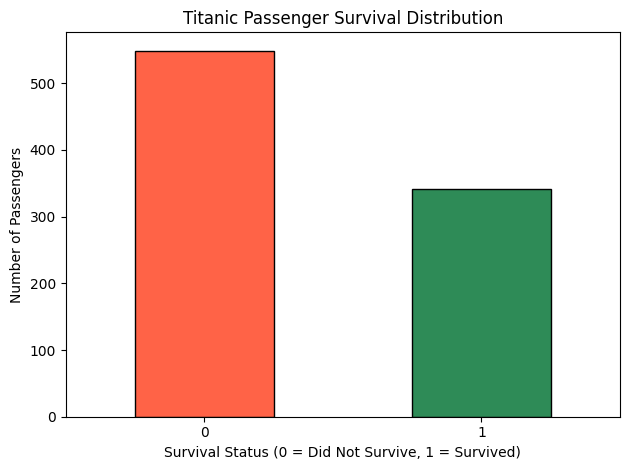

In [3]:
# Count passengers in each survival category
survival_counts = df["Survived"].value_counts().sort_index()

print("Survival counts:")
print(survival_counts)

# Visualize the survival distribution
survival_counts.plot(
    kind="bar",
    color=["tomato", "seagreen"],
    edgecolor="black"
)

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 Survival Rate by Gender

In this section, we compare the survival rates of male and female passengers. This helps us understand whether gender was associated with survival during the Titanic disaster.

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


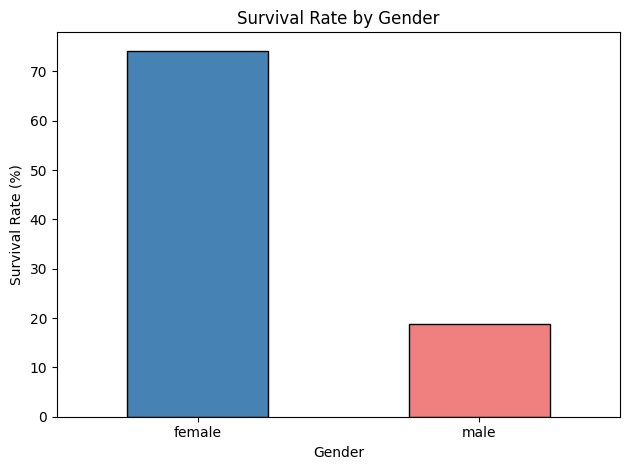

In [4]:
# Calculate survival rate for each gender
gender_survival = df.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by gender (%):")
print(gender_survival.round(2))

# Visualize survival rates
gender_survival.plot(
    kind="bar",
    color=["steelblue", "lightcoral"],
    edgecolor="black"
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Survival Rate by Passenger Class

The Titanic dataset contains three passenger classes: First Class, Second Class, and Third Class. In this analysis, we compare their survival rates to understand how passenger class was associated with survival.

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


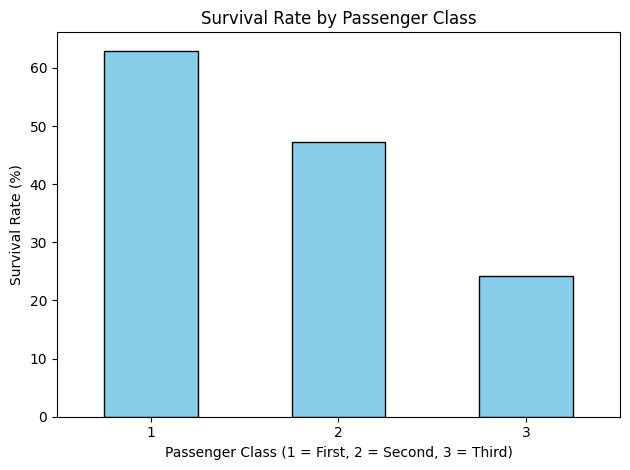

In [5]:
# Calculate survival rate for each passenger class
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by passenger class (%):")
print(class_survival.round(2))

# Visualize survival rates
class_survival.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.4 Age Distribution and Survival

Age may have influenced survival outcomes during the Titanic disaster. In this section, we compare the age distributions of passengers who survived and those who did not, using a box plot and descriptive statistics.

Average age by survival status:
Survived
0    30.03
1    28.29
Name: Age, dtype: float64


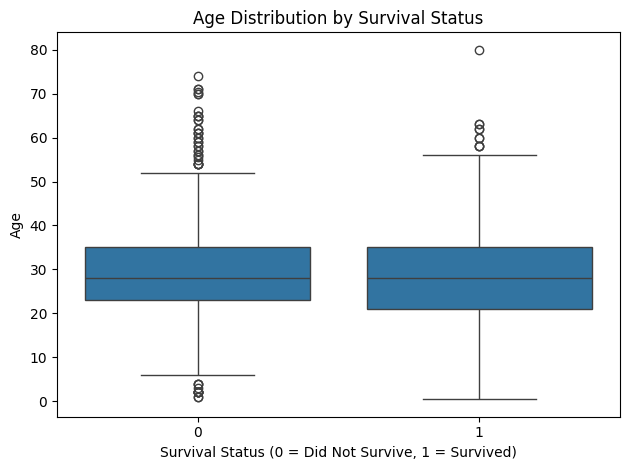

In [6]:
# Compare ages of survivors and non-survivors
print("Average age by survival status:")
print(df.groupby("Survived")["Age"].mean().round(2))

# Create a box plot
sns.boxplot(
    data=df,
    x="Survived",
    y="Age"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

### 3.5 Survival Rate by Family Size

Passengers aboard the Titanic may have travelled alone or with family members. We create a new feature called `FamilySize` by adding the number of siblings/spouses (`SibSp`) and parents/children (`Parch`) to the passenger themselves. We then compare survival rates across different family sizes.

Survival rate by family size (%):
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64


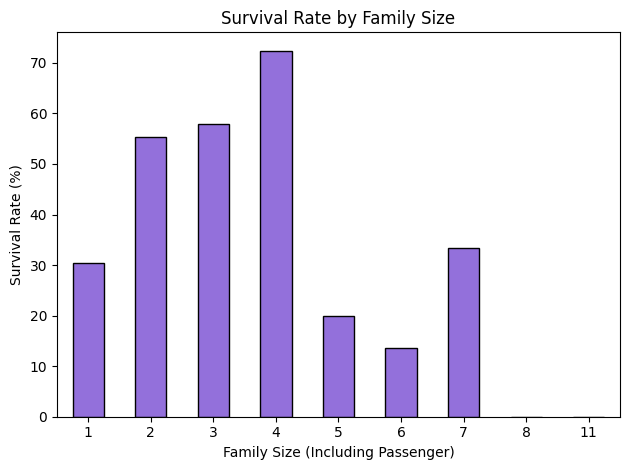

In [7]:
# Create a new feature for family size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Calculate survival rate by family size
family_survival = df.groupby("FamilySize")["Survived"].mean() * 100

print("Survival rate by family size (%):")
print(family_survival.round(2))

# Visualize survival rates
family_survival.plot(
    kind="bar",
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size (Including Passenger)")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.6 Survival Rate by Port of Embarkation

The `Embarked` column identifies the port where each passenger boarded the Titanic. The three ports are Southampton (S), Cherbourg (C), and Queenstown (Q). We compare survival rates across these ports to identify possible patterns in the dataset.

Survival rate by port of embarkation (%):
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64


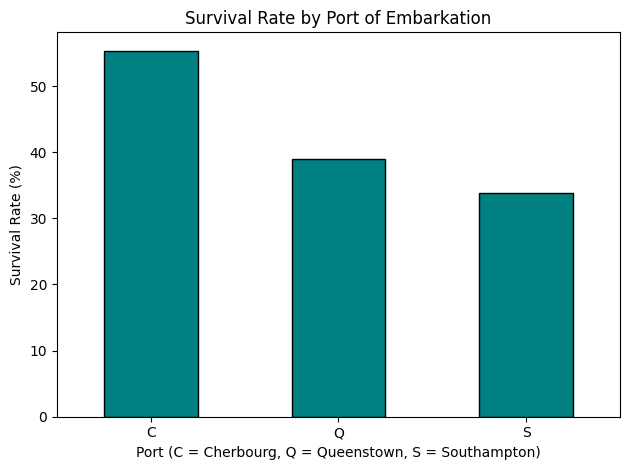

In [8]:
# Calculate survival rate by embarkation port
port_survival = df.groupby("Embarked")["Survived"].mean() * 100

print("Survival rate by port of embarkation (%):")
print(port_survival.round(2))

# Visualize survival rates
port_survival.plot(
    kind="bar",
    color="teal",
    edgecolor="black"
)

plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Port (C = Cherbourg, Q = Queenstown, S = Southampton)")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.7 Correlation Analysis

Correlation analysis helps us identify linear relationships between numerical variables. We use a heatmap to visualize correlations among passenger characteristics and survival. Correlation does not imply causation, and categorical variables such as gender must be encoded numerically before calculating their correlations.

Correlation with Survival:
Survived       1.000
Fare           0.257
Parch          0.082
FamilySize     0.017
PassengerId   -0.005
SibSp         -0.035
Age           -0.065
Pclass        -0.338
Name: Survived, dtype: float64


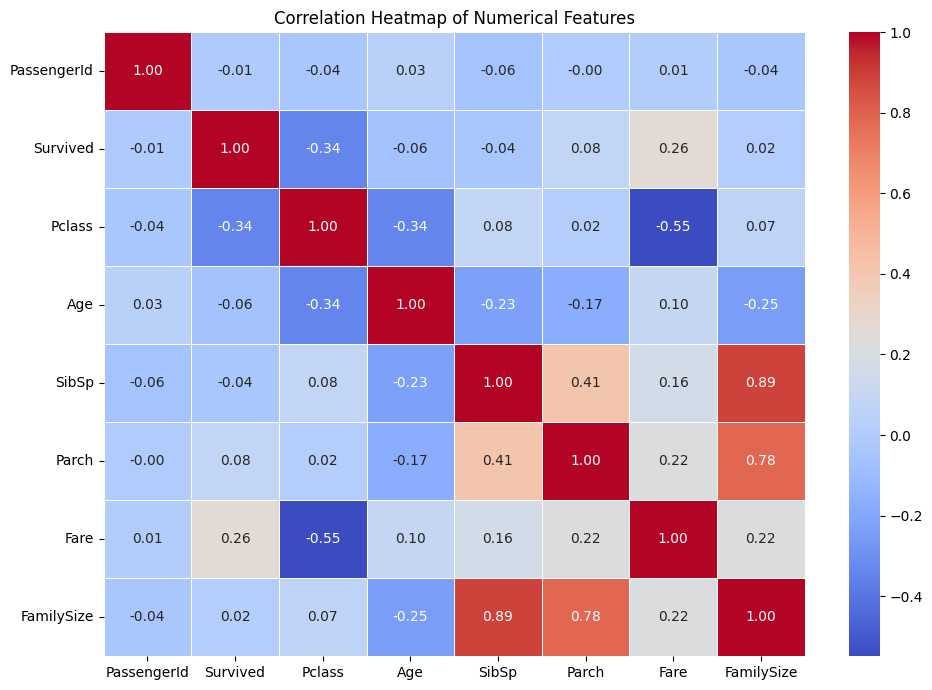

In [9]:
# Select numerical columns for correlation analysis
numeric_df = df.select_dtypes(include="number")

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation with Survival:")
print(correlation_matrix["Survived"].sort_values(ascending=False).round(3))

# Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## 4. Feature Engineering and Data Preparation for Modeling

Machine learning algorithms require suitable numerical input features. In this section, we select relevant passenger attributes, encode categorical variables, and separate the target variable (`Survived`) from the input features.

We use `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, and `Embarked` as predictors. The `Survived` column is the target variable we want to predict.

In [10]:
# Select input features
features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = df[features].copy()
y = df["Survived"].copy()

# Convert categorical features into numerical columns
X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nEncoded feature columns:")
print(X.columns.tolist())

print("\nFirst five rows of prepared features:")
display(X.head())

Input features shape: (891, 8)
Target variable shape: (891,)

Encoded feature columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

First five rows of prepared features:


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,1,0,1
1,1,38.0,1,0,71.2833,0,0,0
2,3,26.0,0,0,7.9250,0,0,1
3,1,35.0,1,0,53.1000,0,0,1
4,3,35.0,0,0,8.0500,1,0,1


### 4.1 Train-Test Split

We divide the dataset into 80% training data and 20% testing data. The model learns patterns from the training set, while the testing set evaluates its ability to predict survival for passengers it has not seen during training.

We use stratified sampling to preserve approximately the same proportion of survivors and non-survivors in both sets. A fixed random state ensures reproducible results.

In [11]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nSurvival distribution in training data:")
print(y_train.value_counts())

print("\nSurvival distribution in testing data:")
print(y_test.value_counts())

Training features: (712, 8)
Testing features: (179, 8)

Training target: (712,)
Testing target: (179,)

Survival distribution in training data:
Survived
0    439
1    273
Name: count, dtype: int64

Survival distribution in testing data:
Survived
0    110
1     69
Name: count, dtype: int64


### 4.2 Model Training

We use Logistic Regression, a supervised machine learning algorithm commonly used for binary classification problems. Since the target variable `Survived` has two possible outcomes (0 or 1), Logistic Regression is suitable for predicting passenger survival.

The model learns relationships between passenger characteristics and survival outcomes from the training dataset.

In [12]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model using the training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 4.3 Model Prediction and Evaluation

After training, we use the model to predict survival outcomes for the testing dataset. We evaluate its performance using accuracy, precision, recall, and the F1-score. These metrics provide a more complete understanding of classification performance than accuracy alone.

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Generate predictions for the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy:  80.45%
Precision: 79.31%
Recall:    66.67%
F1-score:  72.44%

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



### 4.4 Confusion Matrix

A confusion matrix compares the actual survival outcomes with the outcomes predicted by the model. It helps us identify correct predictions, missed survivors, and incorrect survival predictions.

Confusion Matrix:
[[98 12]
 [23 46]]


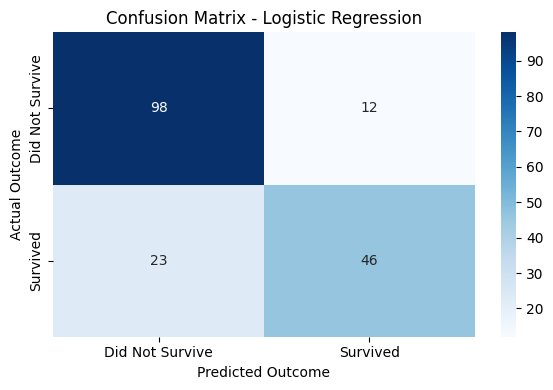

In [14]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

## 5. Key Findings

The exploratory data analysis and Logistic Regression model provided the following insights:

1. **Gender:** Female passengers had a substantially higher survival rate than male passengers in the dataset.
2. **Passenger class:** First-class passengers had higher survival rates than second- and third-class passengers.
3. **Age:** Comparing age distributions helped identify potential differences between survivors and non-survivors.
4. **Family size:** Survival rates varied across family sizes, although some groups contained relatively few passengers.
5. **Port of embarkation:** Survival rates differed between embarkation ports, potentially reflecting differences in passenger characteristics.
6. **Predictive modeling:** Logistic Regression was used to predict survival based on passenger class, gender, age, family relationships, fare, and embarkation port.

These findings describe patterns in the Titanic dataset. They do not establish that any individual characteristic directly caused a passenger to survive or not survive.

## 6. Limitations and Future Improvements

### Limitations

- The dataset represents one historical event and may not generalize to other situations.
- Missing age and embarkation values were imputed, so some original information was unavailable.
- Logistic Regression assumes a relatively simple relationship between input features and the probability of survival.
- The model uses a limited selection of passenger features and may not capture every relevant factor.
- Accuracy alone cannot fully describe performance, so precision, recall, F1-score, and the confusion matrix are also considered.
- The observed relationships are associations and should not be interpreted as proof of causation.

### Future Improvements

- Compare Logistic Regression with Decision Tree and Random Forest models.
- Perform cross-validation and hyperparameter tuning.
- Explore additional features, such as cabin information and ticket characteristics.
- Evaluate model performance across different passenger groups.
- Use a separate validation strategy to select models before final testing.

## 7. Conclusion

This project explored the Titanic passenger dataset and followed an end-to-end data science workflow, including data preparation, exploratory data analysis, feature engineering, model training, and evaluation.

The analysis revealed differences in survival rates across gender, passenger class, family size, and port of embarkation. These patterns helped us understand the dataset and select relevant features for predictive modeling.

A Logistic Regression classifier was trained to predict passenger survival. Its performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. These evaluation methods helped assess both correct predictions and classification errors.

The project provided practical experience with Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn. It also demonstrated the importance of data quality, appropriate feature selection, model evaluation, and acknowledging the limitations of predictive models.

Overall, this project demonstrates how data science techniques can be used to analyze a real-world dataset, identify patterns, and develop a baseline machine learning solution.